# Ejercicio 1 - Preprocesamiento MRI y construcción del dataset 2.5D

## 1. Objetivo

Este notebook transforma las series MRI sagitales seleccionadas en la
etapa anterior en entradas homogéneas para modelos de redes neuronales.

Para cada estudio se realizará:

1. Lectura y ordenamiento espacial de los cortes DICOM.
2. Normalización de intensidades a nivel de volumen.
3. Normalización de la separación entre cortes.
4. Selección de regiones representativas de la serie.
5. Construcción de entradas 2.5D mediante tres cortes contiguos.
6. Redimensionamiento a 224 × 224 píxeles.

Antes de procesar los 546 estudios, el procedimiento se validará
visualmente sobre una pequeña muestra.

In [106]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom

from scipy.ndimage import zoom
from PIL import Image

In [107]:
COMP_PATH = "/kaggle/input/competitions/rsna-knee-abnormality-detection"

TRAIN_DICOM_DIR = os.path.join(
    COMP_PATH,
    "train_series"
)

META_DIR = (
    "/kaggle/input/datasets/"
    "mariomasias/ejercicio-1-metadata"
)

MANIFEST_PATH = os.path.join(
    META_DIR,
    "manifest_sagittal_final.csv"
)

WEAK_PATH = os.path.join(
    META_DIR,
    "weak_500_final.csv"
)

GOLD_SPLIT_PATH = os.path.join(
    META_DIR,
    "gold_split_58.csv"
)

manifest = pd.read_csv(
    MANIFEST_PATH,
    dtype={
        "StudyInstanceUID": str,
        "SeriesInstanceUID": str
    }
)

print("Estudios en manifiesto:", len(manifest))
print(manifest["Grupo"].value_counts())

display(manifest.head())

Estudios en manifiesto: 546
Grupo
WEAK    490
GOLD     56
Name: count, dtype: int64


,Grupo,StudyInstanceUID,SeriesInstanceUID,Tipo_Final,N_Slices,Tamaño_MB,Rows,Columns,SliceThickness,SpacingBetweenSlices,SeriesDescription,ProtocolName,RepetitionTime,EchoTime
0,WEAK,1.2.826.0.1.3680043.8.498.10029520033957968044...,1.2.826.0.1.3680043.8.498.12283902861056341541...,PD,26,20.348200,640,640,3.0,3.600,LT_pd_tse_fs_sag,NaN,3550.000000,36.0
1,WEAK,1.2.826.0.1.3680043.8.498.10061120822929703004...,1.2.826.0.1.3680043.8.498.52617317497828611151...,PD,30,16.001928,528,528,3.0,3.500,PDW_SPAIR,NaN,3875.636963,30.0
2,WEAK,1.2.826.0.1.3680043.8.498.10087350795575215080...,1.2.826.0.1.3680043.8.498.96012886433868321293...,PD_like,35,17.550863,512,512,3.0,3.300,DummySeriesDesc!,NaN,3143.979004,35.0
3,GOLD,1.2.826.0.1.3680043.8.498.10095687747295410396...,1.2.826.0.1.3680043.8.498.37372672584387115708...,PD,36,7.080601,320,320,2.5,2.875,pd_tse_fs_sag,NaN,4790.000000,40.0
4,WEAK,1.2.826.0.1.3680043.8.498.10155611590208164695...,1.2.826.0.1.3680043.8.498.62105522526870664598...,PD,32,14.109434,480,480,3.0,3.300,RT.SAG PDW_TSE_SPAIR,NaN,3426.484863,20.0


## 2. Lectura y ordenamiento de las series DICOM

Los archivos DICOM de una serie no deben ordenarse utilizando únicamente
el nombre del archivo. Cuando la información geométrica está disponible,
los cortes se ordenan utilizando `ImagePositionPatient` e
`ImageOrientationPatient`.

Esto permite reconstruir correctamente el orden espacial del volumen.

In [108]:
def cargar_serie_dicom(study_uid, series_uid):

    ruta = os.path.join(TRAIN_DICOM_DIR,str(study_uid),str(series_uid))

    archivos = [
        os.path.join(ruta, f)
        for f in os.listdir(ruta)
        if f.lower().endswith(".dcm")
    ]

    slices = []

    for archivo in archivos:

        ds = pydicom.dcmread(
            archivo,
            force=True
        )

        # -------------------------
        # Posición espacial
        # -------------------------

        if (
            hasattr(ds, "ImagePositionPatient")
            and hasattr(ds, "ImageOrientationPatient")
        ):

            position = np.asarray(
                ds.ImagePositionPatient,
                dtype=float
            )

            orientation = np.asarray(
                ds.ImageOrientationPatient,
                dtype=float
            )

            row = orientation[:3]
            col = orientation[3:]

            normal = np.cross(row, col)

            posicion = float(
                np.dot(position, normal)
            )

        else:

            posicion = float(
                getattr(
                    ds,
                    "InstanceNumber",
                    len(slices)
                )
            )

        slices.append(
            (posicion, ds)
        )

    slices.sort(
        key=lambda x: x[0]
    )

    return slices

In [109]:
def serie_a_volumen(slices):

    imagenes = []
    posiciones = []

    for posicion, ds in slices:

        img = ds.pixel_array.astype(np.float32)

        slope = float(
            getattr(ds, "RescaleSlope", 1.0)
        )

        intercept = float(
            getattr(ds, "RescaleIntercept", 0.0)
        )

        img = img * slope + intercept

        # Algunas imágenes DICOM utilizan
        # representación monocromática invertida
        if getattr(
            ds,
            "PhotometricInterpretation",
            ""
        ) == "MONOCHROME1":

            img = img.max() - img

        imagenes.append(img)
        posiciones.append(posicion)

    volumen = np.stack(
        imagenes,
        axis=0
    )

    posiciones = np.asarray(
        posiciones,
        dtype=float
    )

    return volumen, posiciones

In [110]:
def obtener_spacing_z(posiciones):

    if len(posiciones) < 2:
        return np.nan

    diferencias = np.abs(
        np.diff(posiciones)
    )

    diferencias = diferencias[
        diferencias > 1e-6
    ]

    if len(diferencias) == 0:
        return np.nan

    return float(np.median(diferencias))

In [111]:
fila = manifest.iloc[0]

slices = cargar_serie_dicom(
    fila["StudyInstanceUID"],
    fila["SeriesInstanceUID"]
)

volumen, posiciones = serie_a_volumen(
    slices
)

spacing_z = obtener_spacing_z(
    posiciones
)

print("Study:", fila["StudyInstanceUID"])
print("Tipo:", fila["Tipo_Final"])
print("Forma del volumen:", volumen.shape)
print("Spacing Z:", spacing_z, "mm")
print("Intensidad mínima:", volumen.min())
print("Intensidad máxima:", volumen.max())

Study: 1.2.826.0.1.3680043.8.498.10029520033957968044048068502185417806
Tipo: PD
Forma del volumen: (26, 640, 640)
Spacing Z: 3.6000011884623113 mm
Intensidad mínima: 0.0
Intensidad máxima: 1085.0


## 3. Normalización y remuestreo espacial

Las series MRI presentan diferente número de cortes y separación entre
ellos. Para obtener entradas comparables, se normaliza la separación
entre cortes a aproximadamente **3.5 mm**, valor cercano a la mediana
observada en las series seleccionadas.

El remuestreo se realiza únicamente sobre el eje de profundidad. De esta
forma, adquisiciones con alta resolución, por ejemplo 0.4 mm entre
cortes, se transforman a una representación comparable con las series
convencionales.

Posteriormente, las intensidades se normalizan a nivel de volumen y los
cortes se redimensionan a 224 × 224 píxeles.

### Normalización de intensidades

In [112]:
def normalizar_volumen(volumen):

    volumen = volumen.astype(np.float32)

    # Utilizamos intensidades distintas de cero
    # para que el fondo no domine los percentiles
    valores = volumen[np.isfinite(volumen) & (volumen != 0)]

    if len(valores) == 0:
        return np.zeros_like(volumen,dtype=np.float32)

    p1, p99 = np.percentile(valores,[1, 99])

    volumen = np.clip(volumen,p1,p99)

    volumen = (volumen - p1) / (p99 - p1 + 1e-8)

    return volumen.astype(np.float32)

### Resampling del eje Z

In [113]:
def resamplear_profundidad(volumen,spacing_actual,spacing_objetivo=3.5):

    if (not np.isfinite(spacing_actual) or spacing_actual <= 0):
        return volumen

    n_original = volumen.shape[0]

    # Longitud física aproximada cubierta
    longitud_mm = (
        (n_original - 1)
        * spacing_actual
    )

    n_nuevo = int(
        round(
            longitud_mm /
            spacing_objetivo
        )
    ) + 1

    n_nuevo = max(
        n_nuevo,
        3
    )

    factor_z = (
        n_nuevo /
        n_original
    )

    volumen_resampleado = zoom(
        volumen,
        zoom=(
            factor_z,
            1,
            1
        ),
        order=1
    )

    return volumen_resampleado

In [114]:
volumen_norm = normalizar_volumen(volumen)

volumen_resampled = resamplear_profundidad(
    volumen_norm,
    spacing_z,
    spacing_objetivo=3.5
)

print("Forma original:",volumen.shape)

print("Forma después del resampling:",volumen_resampled.shape)

print("Rango normalizado:",volumen_resampled.min(),volumen_resampled.max())

Forma original: (26, 640, 640)
Forma después del resampling: (27, 640, 640)
Rango normalizado: 0.0 1.0


### Redimensionar a 224×224

In [115]:
def redimensionar_slice(
    img,
    tamaño=224
):

    img_uint8 = (
        np.clip(img, 0, 1)
        * 255
    ).astype(np.uint8)

    img_pil = Image.fromarray(
        img_uint8
    )

    img_pil = img_pil.resize(
        (tamaño, tamaño),
        Image.Resampling.BILINEAR
    )

    return (
        np.asarray(
            img_pil
        ).astype(np.float32)
        / 255.0
    )

### Ahora construimos el 2.5D

In [116]:
def crear_vistas_2_5d(
    volumen,
    posiciones_relativas=(0.30, 0.50, 0.70),
    tamaño=224
):

    n = volumen.shape[0]

    vistas = []

    for posicion in posiciones_relativas:

        centro = int(
            round(
                posicion * (n - 1)
            )
        )

        # Garantizar que haya un vecino
        # a cada lado
        centro = np.clip(
            centro,
            1,
            n - 2
        )

        indices = [
            centro - 1,
            centro,
            centro + 1
        ]

        canales = []

        for idx in indices:

            img = redimensionar_slice(
                volumen[idx],
                tamaño=tamaño
            )

            canales.append(img)

        stack = np.stack(
            canales,
            axis=0
        )

        vistas.append(stack)

    return np.stack(
        vistas,
        axis=0
    )

In [117]:
vistas = crear_vistas_2_5d(
    volumen_resampled
)

print(
    "Forma dataset 2.5D del estudio:",
    vistas.shape
)

Forma dataset 2.5D del estudio: (3, 3, 224, 224)


Cada posición relativa genera una entrada 2.5D formada por tres
cortes contiguos:

- Corte -1
- Corte central
- Corte +1

Por estudio se generan tres vistas centradas aproximadamente en
30 %, 50 % y 70 % de la profundidad del volumen remuestreado.

In [118]:
def mostrar_vistas_2_5d(
    vistas,
    titulo=""
):

    posiciones = [
        "30%",
        "50%",
        "70%"
    ]

    nombres_canal = [
        "Corte -1",
        "Corte central",
        "Corte +1"
    ]

    fig, axes = plt.subplots(
        3,
        3,
        figsize=(10, 10)
    )

    for i in range(3):

        for j in range(3):

            axes[i, j].imshow(
                vistas[i, j],
                cmap="gray"
            )

            axes[i, j].set_title(
                f"{posiciones[i]} - "
                f"{nombres_canal[j]}"
            )

            axes[i, j].axis("off")

    plt.suptitle(
        titulo,
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

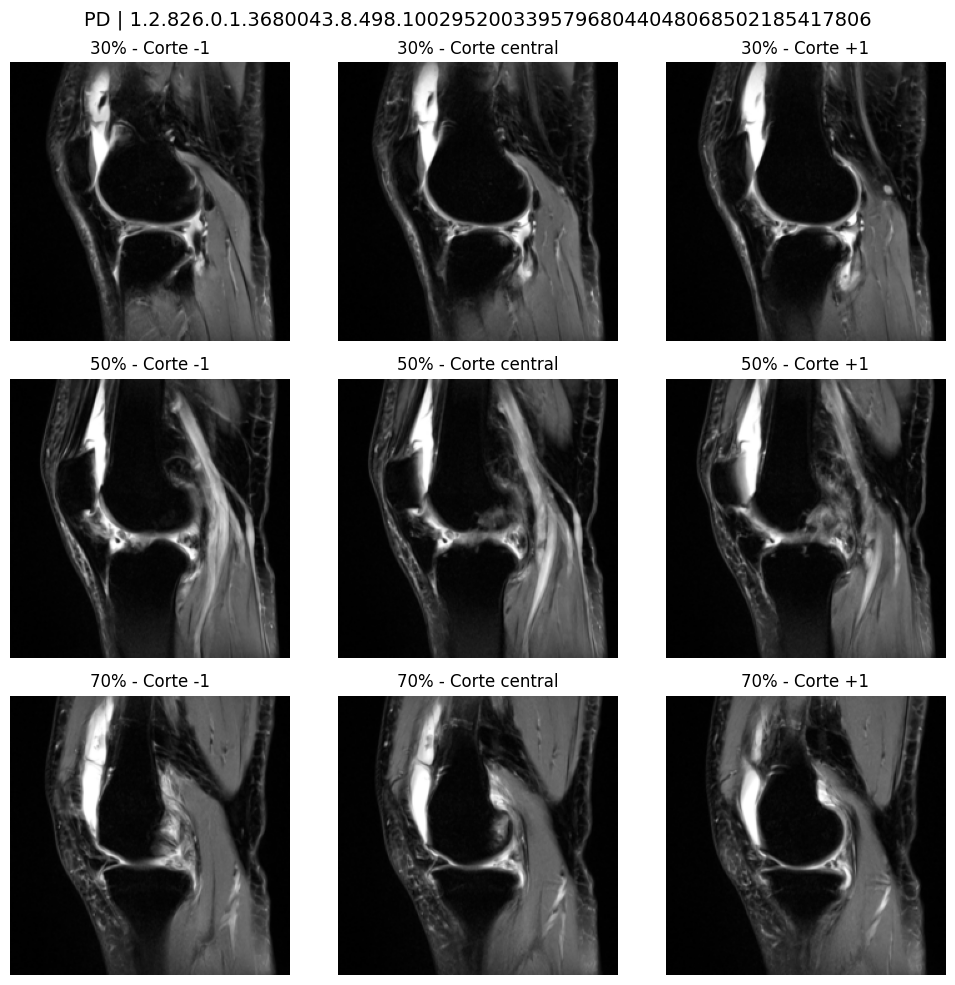

In [119]:
mostrar_vistas_2_5d(
    vistas,
    titulo=(
        f"{fila['Tipo_Final']} | "
        f"{fila['StudyInstanceUID']}"
    )
)

### 320 Cortes

In [120]:
fila_3d = (
    manifest
    .sort_values(
        "N_Slices",
        ascending=False
    )
    .iloc[0]
)

slices_3d = cargar_serie_dicom(
    fila_3d["StudyInstanceUID"],
    fila_3d["SeriesInstanceUID"]
)

volumen_3d, posiciones_3d = (
    serie_a_volumen(
        slices_3d
    )
)

spacing_3d = obtener_spacing_z(
    posiciones_3d
)

volumen_3d_norm = normalizar_volumen(
    volumen_3d
)

volumen_3d_resampled = (
    resamplear_profundidad(
        volumen_3d_norm,
        spacing_3d,
        spacing_objetivo=3.5
    )
)

print(
    "Número original de cortes:",
    volumen_3d.shape[0]
)

print(
    "Spacing original:",
    spacing_3d,
    "mm"
)

print(
    "Número después del resampling:",
    volumen_3d_resampled.shape[0]
)

print(
    "Spacing objetivo:",
    3.5,
    "mm"
)

Número original de cortes: 320
Spacing original: 0.39999676489708236 mm
Número después del resampling: 37
Spacing objetivo: 3.5 mm


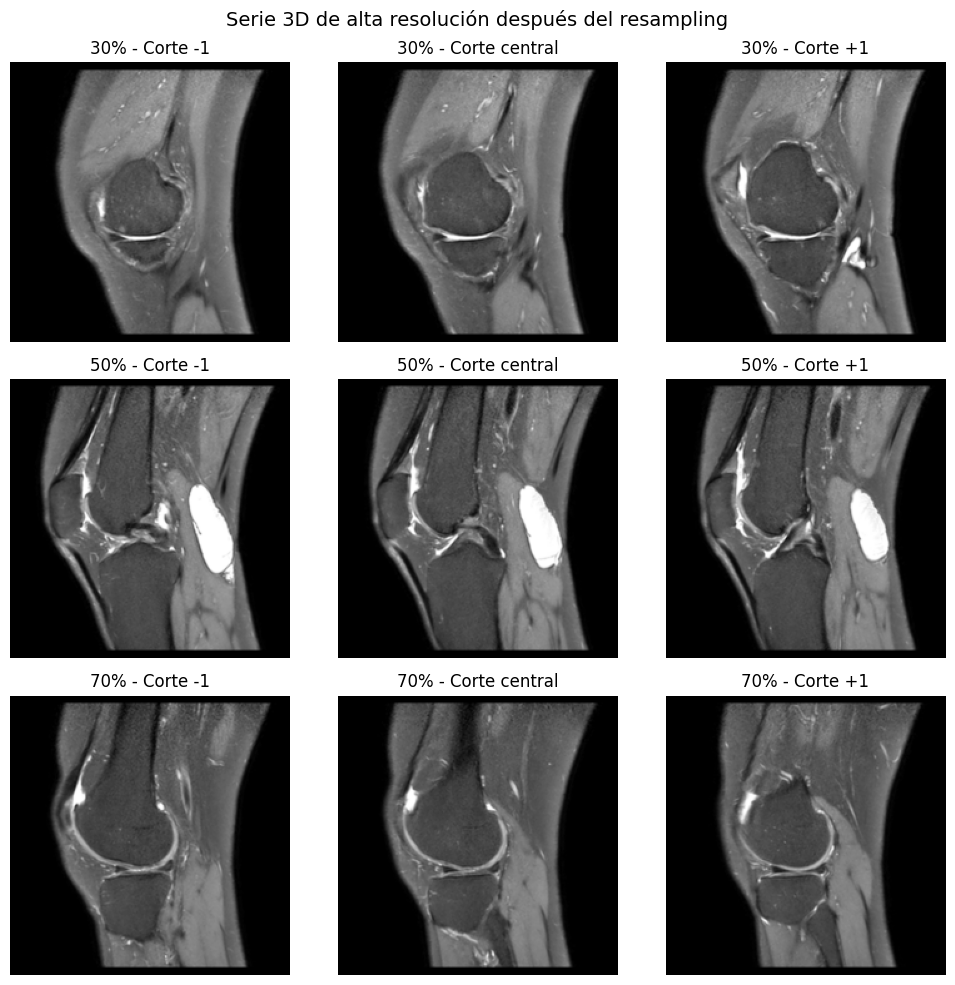

In [121]:
vistas_3d = crear_vistas_2_5d(
    volumen_3d_resampled
)

mostrar_vistas_2_5d(
    vistas_3d,
    titulo=(
        "Serie 3D de alta resolución "
        "después del resampling"
    )
)

## 4. Validación del pipeline sobre estudios representativos

Antes de procesar todo el conjunto, se valida el procedimiento completo
sobre estudios con diferentes tipos de secuencia y características.

Para cada estudio se ejecuta automáticamente:

1. Lectura y ordenamiento DICOM.
2. Construcción del volumen.
3. Cálculo del espaciado entre cortes.
4. Normalización de intensidades.
5. Remuestreo a 3.5 mm.
6. Construcción de tres vistas 2.5D.
7. Redimensionamiento a 224 × 224 píxeles.

In [122]:
def procesar_estudio(row):

    slices = cargar_serie_dicom(row["StudyInstanceUID"],row["SeriesInstanceUID"])

    volumen, posiciones = serie_a_volumen(slices)

    spacing_z = obtener_spacing_z(posiciones)

    volumen_norm = normalizar_volumen(volumen)

    volumen_resampled = resamplear_profundidad(volumen_norm,spacing_z,spacing_objetivo=3.5)

    vistas = crear_vistas_2_5d(volumen_resampled,posiciones_relativas=(0.30, 0.50, 0.70),tamaño=224)

    info = {
        "StudyInstanceUID": row["StudyInstanceUID"],
        "Tipo_Final": row["Tipo_Final"],
        "Slices_originales": volumen.shape[0],
        "Slices_resampleadas": volumen_resampled.shape[0],
        "Spacing_Z": spacing_z,
        "Forma_2_5D": vistas.shape
    }

    return vistas, info

In [123]:
tipos_prueba = [
    "PD",
    "T2",
    "PD_like",
    "T2_like",
    "AMBIGUO"
]

filas_prueba = []

for tipo in tipos_prueba:

    candidatos = manifest[
        manifest["Tipo_Final"] == tipo
    ]

    if len(candidatos) > 0:
        filas_prueba.append(
            candidatos.iloc[0]
        )


Tipo: PD
Cortes: 26 → 27
Spacing: 3.6 mm
Forma 2.5D: (3, 3, 224, 224)


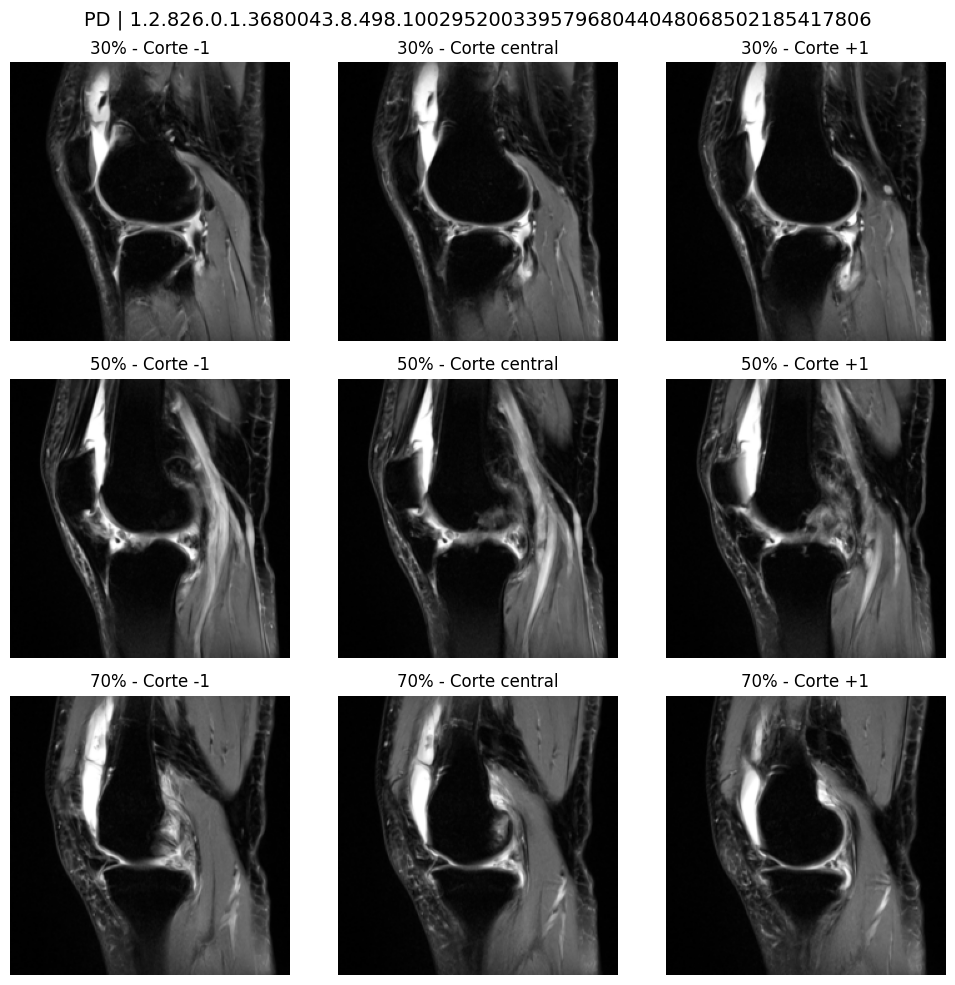


Tipo: T2
Cortes: 30 → 38
Spacing: 4.5 mm
Forma 2.5D: (3, 3, 224, 224)


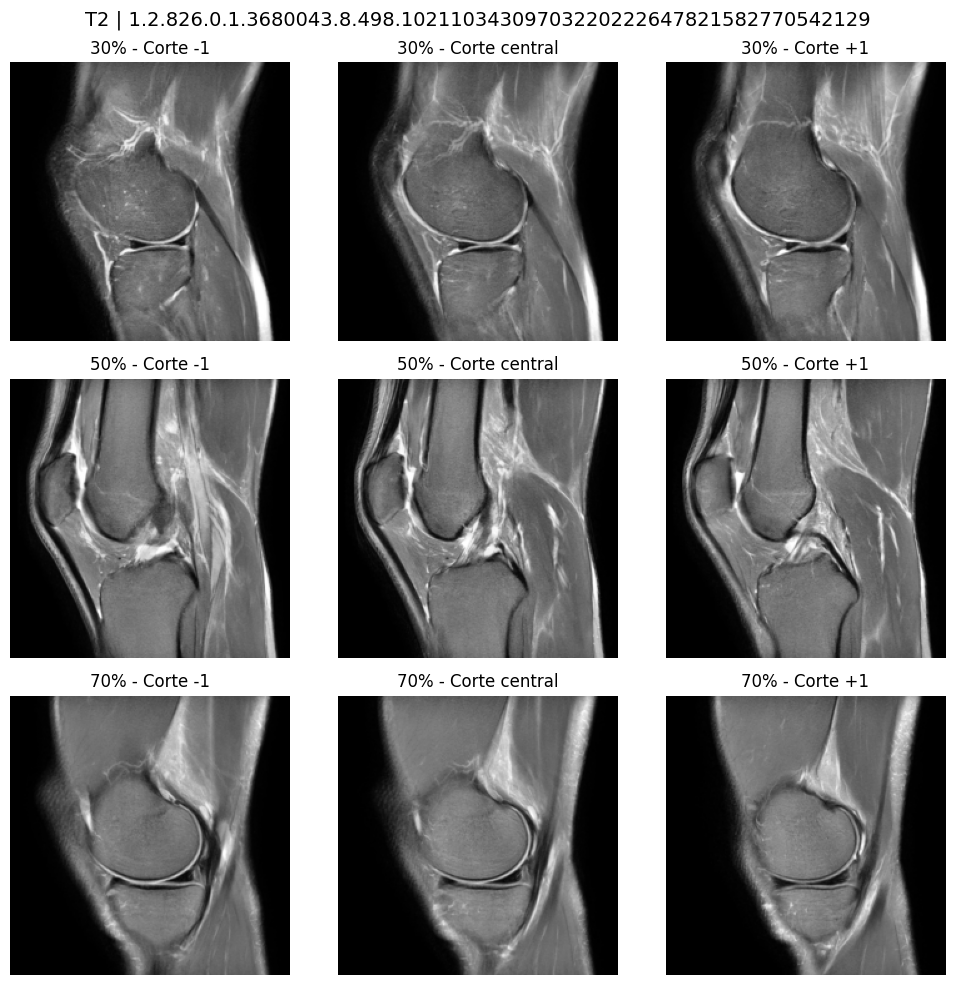


Tipo: PD_like
Cortes: 35 → 33
Spacing: 3.3 mm
Forma 2.5D: (3, 3, 224, 224)


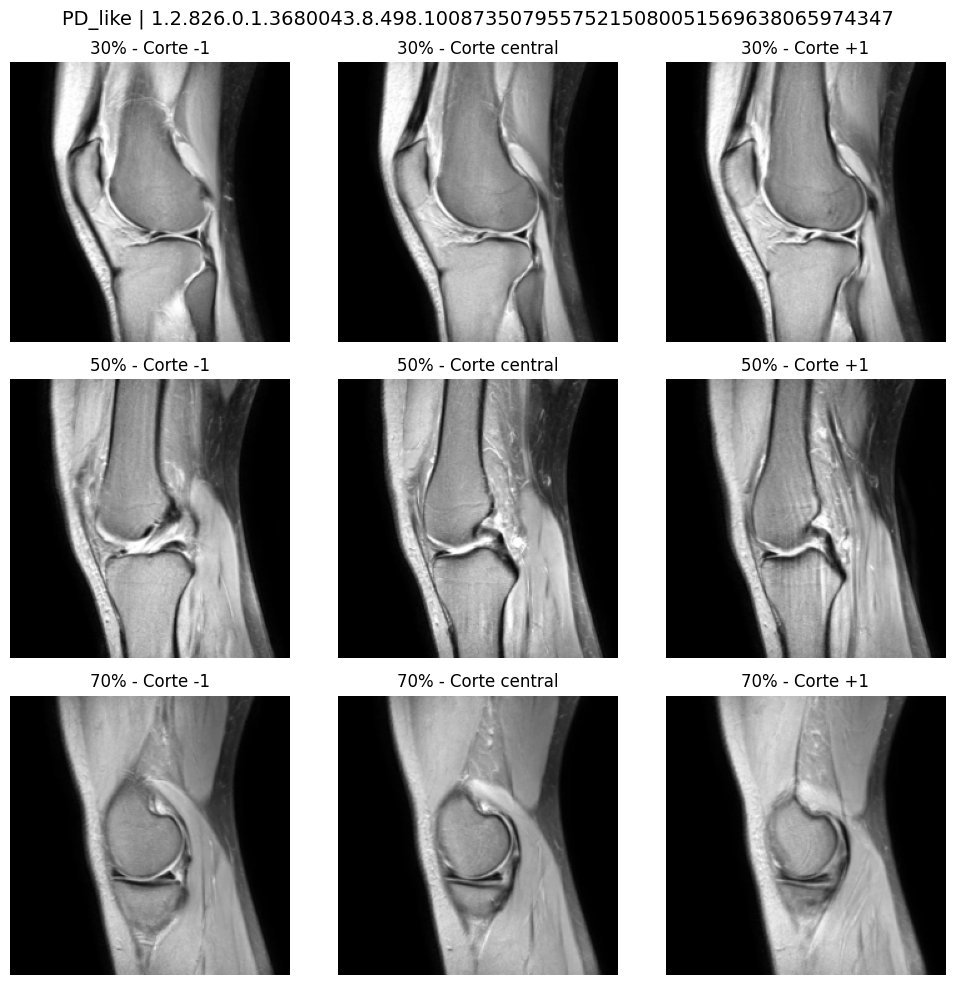


Tipo: T2_like
Cortes: 26 → 30
Spacing: 4.0 mm
Forma 2.5D: (3, 3, 224, 224)


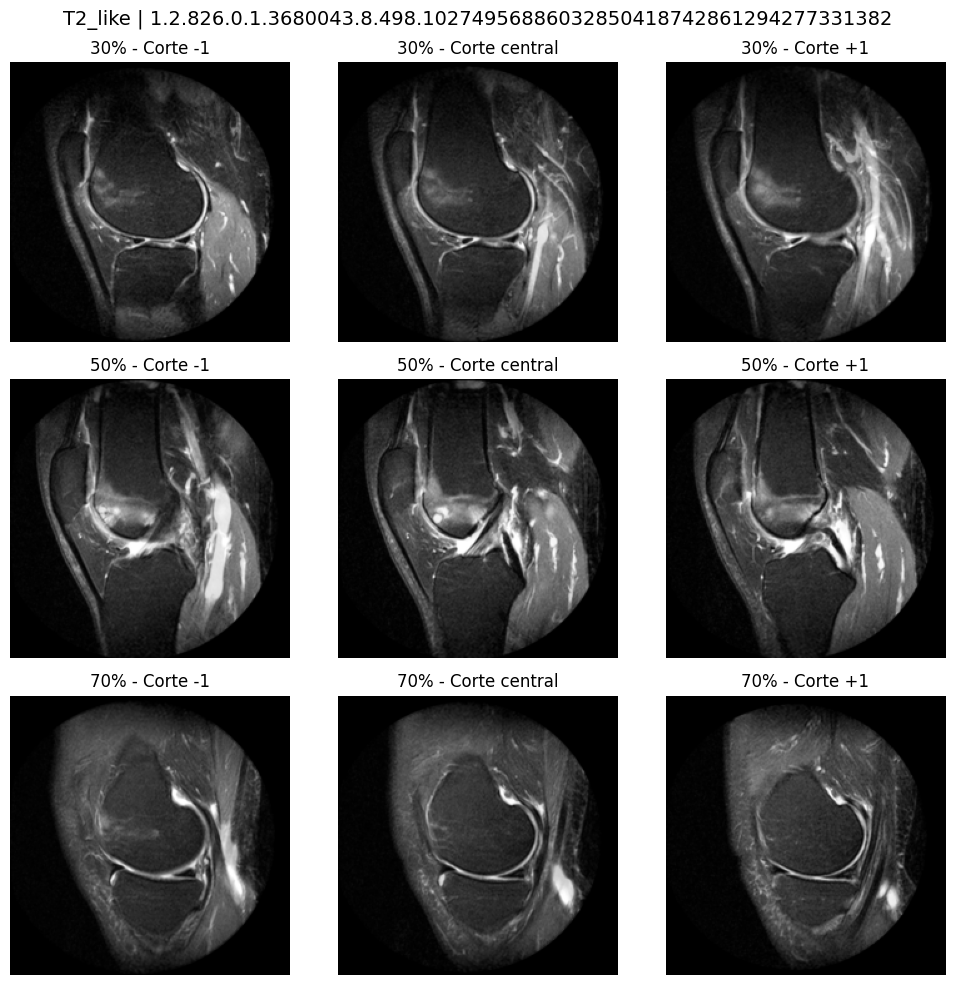


Tipo: AMBIGUO
Cortes: 32 → 30
Spacing: 3.3 mm
Forma 2.5D: (3, 3, 224, 224)


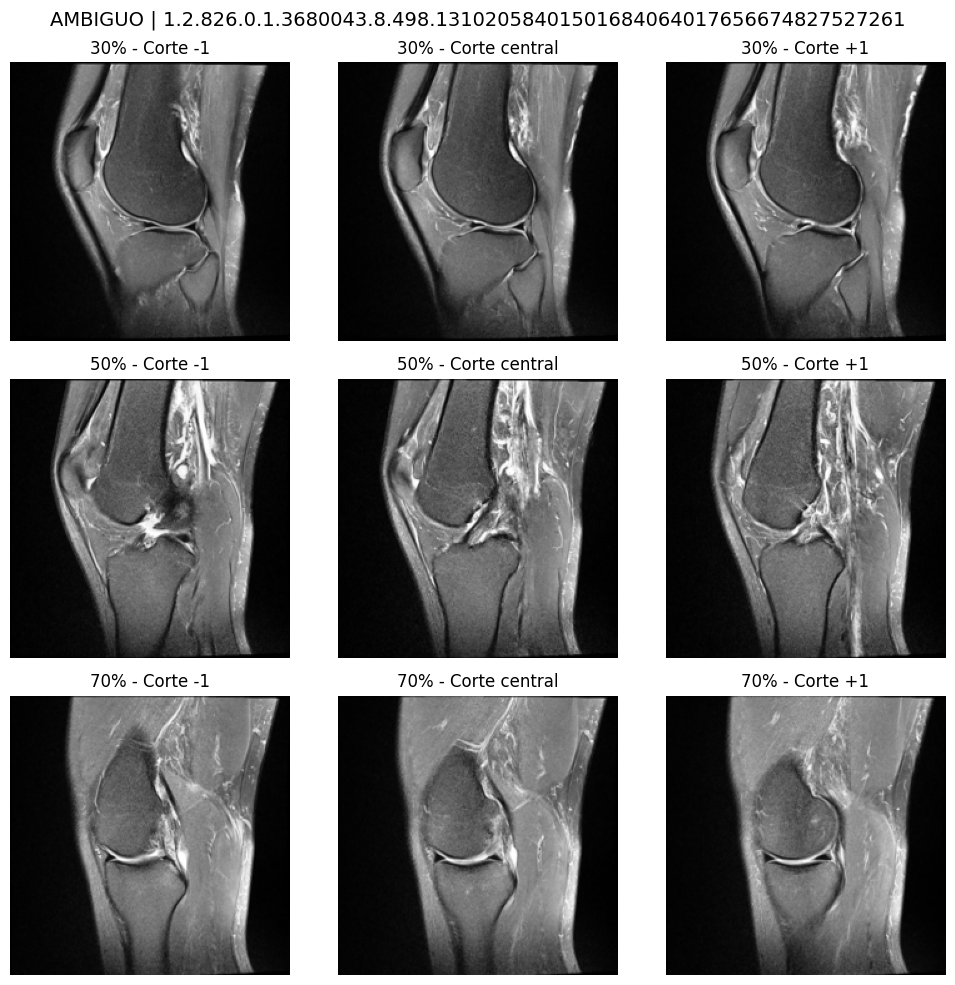

In [124]:
resultados_prueba = []

for row in filas_prueba:

    try:

        vistas_test, info = procesar_estudio(
            row
        )

        resultados_prueba.append(info)

        print("\n==============================")
        print("Tipo:", info["Tipo_Final"])
        print(
            "Cortes:",
            info["Slices_originales"],
            "→",
            info["Slices_resampleadas"]
        )
        print(
            "Spacing:",
            round(info["Spacing_Z"], 3),
            "mm"
        )
        print(
            "Forma 2.5D:",
            info["Forma_2_5D"]
        )

        mostrar_vistas_2_5d(
            vistas_test,
            titulo=(
                f"{info['Tipo_Final']} | "
                f"{info['StudyInstanceUID']}"
            )
        )

    except Exception as e:

        print(
            "ERROR:",
            row["StudyInstanceUID"],
            str(e)
        )

In [125]:
pd.DataFrame(resultados_prueba)

,StudyInstanceUID,Tipo_Final,Slices_originales,Slices_resampleadas,Spacing_Z,Forma_2_5D
0,1.2.826.0.1.3680043.8.498.10029520033957968044...,PD,26,27,3.600001,"(3, 3, 224, 224)"
1,1.2.826.0.1.3680043.8.498.10211034309703220222...,T2,30,38,4.499998,"(3, 3, 224, 224)"
2,1.2.826.0.1.3680043.8.498.10087350795575215080...,PD_like,35,33,3.300000,"(3, 3, 224, 224)"
3,1.2.826.0.1.3680043.8.498.10274956886032850418...,T2_like,26,30,3.999997,"(3, 3, 224, 224)"
4,1.2.826.0.1.3680043.8.498.13102058401501684064...,AMBIGUO,32,30,3.299997,"(3, 3, 224, 224)"


## 5. Integración de etiquetas y definición de splits

Las imágenes preprocesadas deben asociarse con sus etiquetas y con una
partición fija para entrenamiento y evaluación.

Los estudios con etiquetas débiles se utilizarán exclusivamente para
entrenamiento.

Los estudios GOLD conservan la división definida durante la etapa de
weak labeling:

- GOLD DEV: validación del modelo.
- GOLD HOLDOUT: evaluación final.

De esta forma se evita utilizar el conjunto holdout para ajustar el
modelo, los hiperparámetros o los umbrales de decisión.

In [126]:
from pathlib import Path

def buscar_archivo_dataset(nombre):

    candidatos = list(
        Path("/kaggle/input/datasets").rglob(nombre)
    )

    if len(candidatos) == 0:
        raise FileNotFoundError(
            f"No se encontró {nombre}"
        )

    print(
        f"{nombre}:",
        candidatos[0]
    )

    return str(candidatos[0])


WEAK_PATH = buscar_archivo_dataset(
    "weak_500_final.csv"
)

GOLD_SPLIT_PATH = buscar_archivo_dataset(
    "gold_split_58.csv"
)

weak_500_final.csv: /kaggle/input/datasets/mariomasias/ejercicio-1-metadata/weak_500_final.csv
gold_split_58.csv: /kaggle/input/datasets/mariomasias/ejercicio-1-metadata/gold_split_58.csv


In [127]:
weak_500 = pd.read_csv(
    WEAK_PATH,
    dtype={
        "StudyInstanceUID": str
    }
)

gold_split = pd.read_csv(
    GOLD_SPLIT_PATH,
    dtype={
        "StudyInstanceUID": str
    }
)

print(
    "Weak:",
    weak_500.shape
)

print(
    "Gold split:",
    gold_split.shape
)

print("\nDistribución GOLD original:")
print(
    gold_split["GoldSplit"]
    .value_counts()
)

print("\nSplit GOLD con imagen sagital:")
print(
    gold_split["Split_Imagen"]
    .value_counts()
)

Weak: (500, 30)
Gold split: (58, 16)

Distribución GOLD original:
GoldSplit
DEV        40
HOLDOUT    18
Name: count, dtype: int64

Split GOLD con imagen sagital:
Split_Imagen
validation              39
test                    17
excluded_no_sagittal     2
Name: count, dtype: int64


### Unificamos las 12 etiquetas

In [128]:
labels = [
    "ACL",
    "MCL",
    "Medial Meniscus",
    "Lateral Meniscus",
    "Medial OA",
    "Lateral OA",
    "PF OA",
    "Effusion",
    "Synovitis",
    "Baker's",
    "Contusion",
    "Fracture"
]


weak_cols = {
    "ACL": "ACL_weak",
    "MCL": "MCL_weak",
    "Medial Meniscus": "Medial_Meniscus_weak",
    "Lateral Meniscus": "Lateral_Meniscus_weak",
    "Medial OA": "Medial_OA_weak",
    "Lateral OA": "Lateral_OA_weak",
    "PF OA": "PF_OA_weak",

    # usamos la versión con control de calidad
    "Effusion": "Effusion_weak_qc",

    "Synovitis": "Synovitis_weak",
    "Baker's": "Bakers_weak",
    "Contusion": "Contusion_weak",
    "Fracture": "Fracture_weak"
}

In [129]:
weak_meta = (
    manifest[
        manifest["Grupo"] == "WEAK"
    ]
    .merge(
        weak_500,
        on="StudyInstanceUID",
        how="left",
        validate="one_to_one"
    )
)

weak_meta["Split"] = "train"
weak_meta["LabelSource"] = "WEAK"

for label, col_weak in weak_cols.items():

    weak_meta[label] = (
        weak_meta[col_weak]
        .astype(int)
    )

print(
    "WEAK con imagen:",
    len(weak_meta)
)

WEAK con imagen: 490


In [130]:
gold_meta = (
    manifest[
        manifest["Grupo"] == "GOLD"
    ]
    .merge(
        gold_split,
        on="StudyInstanceUID",
        how="left",
        validate="one_to_one"
    )
)

gold_meta["Split"] = (
    gold_meta["Split_Imagen"]
)

gold_meta["LabelSource"] = "GOLD"

print("GOLD con imagen:",len(gold_meta))

print(gold_meta["Split"].value_counts())

GOLD con imagen: 56
Split
validation    39
test          17
Name: count, dtype: int64


### Construyendo el INDICE MAESTRO

In [131]:
columnas_finales = [
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "Grupo",
    "Tipo_Final",
    "Split",
    "LabelSource"
] + labels


dataset_meta = pd.concat(
    [
        weak_meta[columnas_finales],
        gold_meta[columnas_finales]
    ],
    ignore_index=True
)

print(
    "Total estudios:",
    len(dataset_meta)
)

print("\nSplit:")
print(dataset_meta["Split"].value_counts())
print("\nValores faltantes en etiquetas:",dataset_meta[labels].isna().sum().sum())

Total estudios: 546

Split:
Split
train         490
validation     39
test           17
Name: count, dtype: int64

Valores faltantes en etiquetas: 0


In [140]:
# Convertir todas las etiquetas a enteros pequeños una sola vez
dataset_meta[labels] = (
    dataset_meta[labels]
    .astype(np.int8)
)

# Verificar valores permitidos por split
for split in ["train", "validation", "test"]:

    subset = dataset_meta[dataset_meta["Split"] == split]

    valores = sorted(
        pd.unique(
            subset[labels]
            .values
            .ravel()
        )
    )

    print(split, "→", valores)

train → [np.int8(-1), np.int8(0), np.int8(1)]
validation → [np.int8(0), np.int8(1)]
test → [np.int8(0), np.int8(1)]


## 7. Conclusiones

Se procesaron correctamente los 546 estudios seleccionados, sin errores.

Cada serie MRI sagital fue transformada en una representación 2.5D
homogénea compuesta por tres posiciones relativas del volumen
(30 %, 50 % y 70 %), cada una formada por tres cortes contiguos.

El conjunto final presenta dimensiones:

**546 × 3 × 3 × 224 × 224**

y fue almacenado en formato `uint8`, reduciendo el volumen de datos
a aproximadamente 235 MB.

La partición final utilizada es:

- 490 estudios WEAK para entrenamiento.
- 39 estudios GOLD DEV para validación.
- 17 estudios GOLD HOLDOUT para evaluación final.

Las etiquetas `-1` aparecen únicamente en el conjunto WEAK y representan
abstenciones que serán ignoradas mediante una máscara durante el cálculo
de la función de pérdida.

El dataset generado queda preparado para el entrenamiento de los modelos
de clasificación multietiqueta.

                    546 estudios
                         │
        ┌─────────────────────┼───────────────────┐
        │                    │                │
      TRAIN             VALIDATION         TEST
        │                    │                │
   490 WEAK               39 GOLD          17 GOLD
        │                    │                │
   -1 / 0 / 1              0 / 1            0 / 1
        │                    │                │
 entrenar CNN          ajustar modelo    evaluación
                        y thresholds       FINAL

## 6. Generación del dataset 2.5D final

Una vez validado el preprocesamiento y definidos los splits,
se procesan los 546 estudios seleccionados.

Cada estudio se transforma en una representación homogénea de:

**3 vistas × 3 cortes contiguos × 224 × 224 píxeles**

Las imágenes se almacenan en formato `uint8` para reducir el tamaño
en disco y las etiquetas se almacenan en un archivo CSV asociado.

In [141]:
from tqdm.auto import tqdm
from numpy.lib.format import open_memmap

OUTPUT_DIR = "/kaggle/working/dataset_2_5d"

os.makedirs(OUTPUT_DIR,exist_ok=True)

IMAGE_PATH = os.path.join(OUTPUT_DIR,"images_2_5d_uint8.npy")

METADATA_PATH = os.path.join(OUTPUT_DIR,"metadata_2_5d.csv")

N = len(dataset_meta)

print("Estudios a procesar:", N)

print("Forma final:",(N, 3, 3, 224, 224))

Estudios a procesar: 546
Forma final: (546, 3, 3, 224, 224)


In [142]:
imagenes_memmap = open_memmap(
    IMAGE_PATH,
    mode="w+",
    dtype=np.uint8,
    shape=(
        N,
        3,
        3,
        224,
        224
    )
)

registros = []
errores = []

for i, (_, row) in enumerate(
    tqdm(
        dataset_meta.iterrows(),
        total=N,
        desc="Procesando MRI"
    )
):

    try:

        vistas, info = procesar_estudio(
            row
        )

        vistas_uint8 = (
            np.clip(
                vistas,
                0,
                1
            )
            * 255
        ).round().astype(
            np.uint8
        )

        imagenes_memmap[i] = vistas_uint8

        registros.append({
            "ImageIndex": i,
            "StudyInstanceUID":
                row["StudyInstanceUID"],
            "Slices_originales":
                info["Slices_originales"],
            "Slices_resampleadas":
                info["Slices_resampleadas"],
            "Spacing_Z":
                info["Spacing_Z"],
            "Procesado_OK": True
        })

    except Exception as e:

        errores.append({
            "ImageIndex": i,
            "StudyInstanceUID":
                row["StudyInstanceUID"],
            "Error": str(e)
        })

        registros.append({
            "ImageIndex": i,
            "StudyInstanceUID":
                row["StudyInstanceUID"],
            "Slices_originales":
                np.nan,
            "Slices_resampleadas":
                np.nan,
            "Spacing_Z":
                np.nan,
            "Procesado_OK": False
        })

imagenes_memmap.flush()

del imagenes_memmap

print("\nProcesamiento terminado.")
print("Correctos:", N - len(errores))
print("Errores:", len(errores))

Procesando MRI:   0%|          | 0/546 [00:00<?, ?it/s]


Procesamiento terminado.
Correctos: 546
Errores: 0


In [143]:
# ============================================================
# GUARDAR METADATA FINAL
# ============================================================

registro_procesamiento = pd.DataFrame(
    registros
)

metadata_final = dataset_meta.copy()

metadata_final.insert(
    0,
    "ImageIndex",
    np.arange(len(metadata_final))
)

metadata_final = metadata_final.merge(
    registro_procesamiento.drop(
        columns=["StudyInstanceUID"]
    ),
    on="ImageIndex",
    how="left",
    validate="one_to_one"
)

metadata_final.to_csv(
    METADATA_PATH,
    index=False
)

print(
    "Metadata guardada:",
    METADATA_PATH
)

print(
    "Filas:",
    len(metadata_final)
)

print("\nSplit:")
print(
    metadata_final["Split"]
    .value_counts()
)

print("\nProcesamiento:")
print(
    metadata_final["Procesado_OK"]
    .value_counts()
)

display(
    metadata_final.head()
)

Metadata guardada: /kaggle/working/dataset_2_5d/metadata_2_5d.csv
Filas: 546

Split:
Split
train         490
validation     39
test           17
Name: count, dtype: int64

Procesamiento:
Procesado_OK
True    546
Name: count, dtype: int64


,ImageIndex,StudyInstanceUID,SeriesInstanceUID,Grupo,Tipo_Final,Split,LabelSource,ACL,MCL,Medial Meniscus,...,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture,Slices_originales,Slices_resampleadas,Spacing_Z,Procesado_OK
0,0,1.2.826.0.1.3680043.8.498.10029520033957968044...,1.2.826.0.1.3680043.8.498.12283902861056341541...,WEAK,PD,train,WEAK,1,1,1,...,-1,1,1,-1,1,-1,26,27,3.600001,True
1,1,1.2.826.0.1.3680043.8.498.10061120822929703004...,1.2.826.0.1.3680043.8.498.52617317497828611151...,WEAK,PD,train,WEAK,-1,-1,1,...,-1,1,-1,1,-1,-1,30,30,3.500004,True
2,2,1.2.826.0.1.3680043.8.498.10087350795575215080...,1.2.826.0.1.3680043.8.498.96012886433868321293...,WEAK,PD_like,train,WEAK,0,0,-1,...,0,0,0,0,0,0,35,33,3.300000,True
3,3,1.2.826.0.1.3680043.8.498.10155611590208164695...,1.2.826.0.1.3680043.8.498.62105522526870664598...,WEAK,PD,train,WEAK,1,0,-1,...,0,0,0,0,0,0,32,30,3.299998,True
4,4,1.2.826.0.1.3680043.8.498.10161011217774350674...,1.2.826.0.1.3680043.8.498.10027425647703671514...,WEAK,PD_like,train,WEAK,0,0,1,...,0,1,-1,-1,0,0,32,30,3.300003,True


In [144]:
# ============================================================
# VERIFICACIÓN DEL DATASET DE IMÁGENES
# ============================================================

imagenes_check = np.load(
    IMAGE_PATH,
    mmap_mode="r"
)

print(
    "Forma:",
    imagenes_check.shape
)

print(
    "Tipo:",
    imagenes_check.dtype
)

print(
    "Mínimo:",
    imagenes_check.min()
)

print(
    "Máximo:",
    imagenes_check.max()
)

print(
    "Tamaño en MB:",
    round(
        os.path.getsize(IMAGE_PATH)
        / 1024**2,
        2
    )
)

Forma: (546, 3, 3, 224, 224)
Tipo: uint8
Mínimo: 0
Máximo: 255
Tamaño en MB: 235.14


In [145]:
# ============================================================
# COMPROBACIÓN DE CONSISTENCIA
# ============================================================

assert len(metadata_final) == imagenes_check.shape[0]

assert metadata_final["ImageIndex"].tolist() == list(
    range(len(metadata_final))
)

assert metadata_final["StudyInstanceUID"].is_unique

assert metadata_final["Procesado_OK"].all()

print("✓ Número de imágenes correcto")
print("✓ ImageIndex consistente")
print("✓ StudyInstanceUID únicos")
print("✓ Todos los estudios procesados correctamente")

✓ Número de imágenes correcto
✓ ImageIndex consistente
✓ StudyInstanceUID únicos
✓ Todos los estudios procesados correctamente


## 7. Conclusiones

Se procesaron correctamente los 546 estudios seleccionados, sin errores.

Cada serie MRI sagital fue transformada en una representación 2.5D
homogénea compuesta por tres posiciones relativas del volumen
(30 %, 50 % y 70 %), cada una formada por tres cortes contiguos.

El conjunto final presenta dimensiones:

**546 × 3 × 3 × 224 × 224**

y fue almacenado en formato `uint8`, reduciendo el volumen de datos
a aproximadamente 235 MB.

La partición final utilizada es:

- 490 estudios WEAK para entrenamiento.
- 39 estudios GOLD DEV para validación.
- 17 estudios GOLD HOLDOUT para evaluación final.

Las etiquetas `-1` aparecen únicamente en el conjunto WEAK y representan
abstenciones que serán ignoradas mediante una máscara durante el cálculo
de la función de pérdida.

El dataset generado queda preparado para el entrenamiento de los modelos
de clasificación multietiqueta.